AP24110011365
S.Keerthi
Section-M

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler                    #Ap24110011365
from sklearn.decomposition import PCA

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving WineQT.csv to WineQT (1).csv


In [ ]:
import pandas as pd

df = pd.read_csv('WineQT.csv')

print(df.head())
print("Dataset shape:", df.shape)                    #Ap24110011365

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  Id  
0      9.4        5   0  
1      9.8        5   1  
2      9

In [ ]:
X = df.select_dtypes(include=['number'])

print("Number of features:", X.shape[1])

Number of features: 13


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-0.52157961  0.93933222 -1.36502663 -0.46642142 -0.23139486 -0.45046702
  -0.3636101   0.55585438  1.27069495 -0.57365783 -0.96338181 -0.81572437
  -1.73561799]
 [-0.29259344  1.94181282 -1.36502663  0.05006018  0.23424656  0.91591972
   0.64347653  0.03616459 -0.70892755  0.1308811  -0.59360107 -0.81572437
  -1.73346186]
 [-0.29259344  1.27349242 -1.16156762 -0.17128908  0.10725344 -0.06007081
   0.24674544  0.14010255 -0.32577481 -0.04525363 -0.59360107 -0.81572437
  -1.73130573]
 [ 1.65378902 -1.39978919  1.48339955 -0.46642142 -0.25256038  0.1351273
   0.4298521   0.65979234 -0.96436271 -0.45623467 -0.59360107  0.42578423
  -1.7291496 ]
 [-0.52157961  0.93933222 -1.36502663 -0.46642142 -0.23139486 -0.45046702
  -0.3636101   0.55585438  1.27069495 -0.57365783 -0.96338181 -0.81572437
  -1.72699347]]


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print(X_pca[:5])

[[-1.2151326  -1.79455548]
 [-0.46743535 -2.4779897 ]
 [-0.40169488 -1.87194873]
 [ 2.64524685  0.10049343]
 [-1.2169159  -1.79291027]]


In [ ]:
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

print(pca_df.head())
print("New dataset shape:", pca_df.shape)

        PC1       PC2
0 -1.215133 -1.794555
1 -0.467435 -2.477990
2 -0.401695 -1.871949
3  2.645247  0.100493
4 -1.216916 -1.792910
New dataset shape: (1143, 2)


In [ ]:
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("Total variance retained:",
      pca.explained_variance_ratio_.sum() * 100, "%")

Explained variance ratio:
[0.25192323 0.17625364]
Total variance retained: 42.817686758664294 %


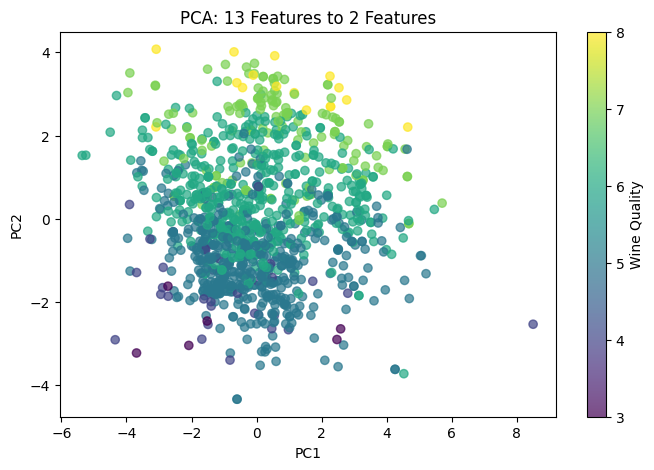

In [ ]:
plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    c=df['quality'],                        #Ap24110011365
    cmap='viridis',
    alpha=0.7
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA: 13 Features to 2 Features')

plt.colorbar(scatter, label='Wine Quality')
plt.show()

In [ ]:
pca = PCA(n_components=3)

X_pca = pca.fit_transform(X_scaled)

print(X_pca[:5])

[[-1.2151326  -1.79455548 -1.53760979]
 [-0.46743535 -2.4779897   0.07017969]
 [-0.40169488 -1.87194873 -0.73697061]
 [ 2.64524685  0.10049343 -0.05032297]
 [-1.2169159  -1.79291027 -1.53652489]]


In [ ]:
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("Total variance retained:",
      pca.explained_variance_ratio_.sum() * 100, "%")

Explained variance ratio:
[0.25192323 0.17625364 0.13093072]
Total variance retained: 55.91075862373802 %


Question 1: What happens if we change the number of components?
Change PCA(n_components=2) to PCA(n_components=3).



 How many features are present after reduction?

Ans: There will be three features after reduction  PCA-1,PCA-2,PCA-3.



 Does the number of samples change?

Ans: No the number of samples doesnot change because we reduced the features of the data set.So no.of samples will be same as before.


 Does the total variance retained increase or decrease?

Ans: The  total variance retained increases because the no.of principle compontents increases then the total variance retained also increases

In [ ]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)

print("Explained variance ratio:",
      pca.explained_variance_ratio_)
print("Total variance retained:",
      pca.explained_variance_ratio_.sum() * 100, "%")

Explained variance ratio: [9.94582078e-01 5.14068487e-03 2.47996601e-04]
Total variance retained: 99.99707597241672 %


Question 2: What happens if standardization is removed?
Replace X_scaled with X in the PCA transformation.

 Does the explained variance ratio change?

Ans: Yes. The explained variance ratio generally changes when standardization is removed because the original features have different numerical scales.

 Why might features with larger numerical scales influence PCA more strongly?

Ans:PCA identifies directions with maximum variance. Features with larger numerical scales can have greater variance and may dominate the principal components.

 Is standardization always necessary?

Ans:No. Standardization is recommended when features have different scales or units. It may not be necessary when all features have comparable scales or when their original scales are intentionally meaningful.

In [ ]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

for i, variance in enumerate(cumulative_variance, start=1):
    print(f"{i} components: {variance * 100:.2f}%")

print("Variance retained with 3 components:",
      cumulative_variance[-1] * 100, "%")

# Find components needed for at least 90% variance
pca_all = PCA()
pca_all.fit(X_scaled)

all_cumulative = np.cumsum(pca_all.explained_variance_ratio_)
components_90 = np.argmax(all_cumulative >= 0.90) + 1

print("Components needed for 90% variance:", components_90)

1 components: 25.19%
2 components: 42.82%
3 components: 55.91%
Variance retained with 3 components: 55.91075862373802 %
Components needed for 90% variance: 9


Question 3: What happens if we retain more components?
Try 1, 2, 3, 5 and 10 principal components.

 How does the cumulative explained variance change?

Ans:Cumulative explained variance increases or stays the same as more principal components are added because each component captures additional variance.

 How many components are needed to retain at least 90% of the variance?

Ans:The number depends on the dataset. Run the code for Question 3 and check the printed result for Components needed for 90% variance.

 Is reducing to two components always the best choice?

Ans:No. Two components are useful for visualization, but they may discard important information. More components may be needed to retain at least 90% of the variance.

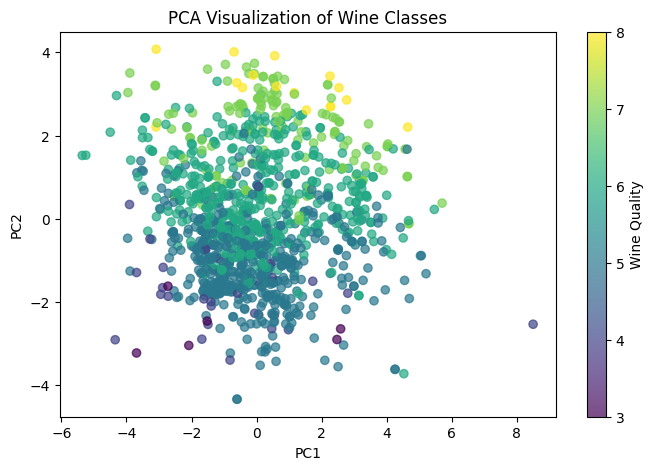

Variance retained by 3 components: 55.91075862373802 %


In [ ]:
# Use 3 components, then plot PC1 and PC2
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca, columns=['PC1', 'PC2', 'PC3']
)

pca_df['quality'] = df['quality'].values

plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    c=pca_df['quality'],
    cmap='viridis',
    alpha=0.7
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA Visualization of Wine Classes')
plt.colorbar(scatter, label='Wine Quality')
plt.show()

print("Variance retained by 3 components:",
      pca.explained_variance_ratio_.sum() * 100, "%")

Question 4: What happens to the visualization?
Plot the first two principal components and observe the three wine classes.

 Are the classes clearly separated?

Ans::Not necessarily. Wine quality classes may overlap in the PCA plot because PCA focuses on capturing variance rather than separating classes.

 What information might be lost when reducing 13 features to 2?

Ans:Some information about the original wine features may be lost because only the first two principal components are displayed, while the remaining components are discarded from the visualization.



 Does PCA use the class labels to create the components?

Ans:No. PCA is an unsupervised learning technique. It creates components from the input features without using the wine quality labels. In our code, the labels are used only to color the points in the graph.


In [ ]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca, columns=['PC1', 'PC2', 'PC3']
)

print("Original feature names:")
print(X.columns.tolist())

print("\nFirst 5 rows of new PCA features:")
print(pca_df.head())

print("\nOriginal data shape:", X.shape)
print("Reduced data shape:", pca_df.shape)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

Original feature names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']

First 5 rows of new PCA features:
        PC1       PC2       PC3
0 -1.215133 -1.794555 -1.537610
1 -0.467435 -2.477990  0.070180
2 -0.401695 -1.871949 -0.736971
3  2.645247  0.100493 -0.050323
4 -1.216916 -1.792910 -1.536525

Original data shape: (1143, 13)
Reduced data shape: (1143, 3)

Explained variance ratio:
[0.25192323 0.17625364 0.13093072]


Question 5: Does PCA select existing features?

 Are the two principal components original Wine dataset columns?

Ans:No. PC1 and PC2 are new features created by combining information from the original numerical features. With n_components=3, the output contains PC1, PC2, and PC3.

 What is the diƯerence between feature selection and feature extraction?

Ans:Feature Selection
1. Selects existing features from the dataset.
2. Original columns are retained.
3. Example: Selecting alcohol and acidity from the Wine dataset.
Feature Extraction
1. Creates new features from existing features.
2. New columns are created.
3. Example: Creating PC1, PC2, and PC3 using PCA.


 Why is PCA considered a feature extraction technique?

Ans:PCA is a feature extraction technique because it transforms the original features into new principal components. These components represent the data using fewer dimensions while preserving as much variance as possible.
